# Proyek Pengganti UTS Pembelajaran Mesin Lanjut
#Track A: WiFi CSI Human Activity Recognition (HAR)
#*WiFi CSI-Based Human Activity Recognition on UT-HAR Dataset Using 1D-CNN and Bi-LSTM Attention*
**Kelompok 5**
1. Muhammad Al Fath 2311511013
2. Muhammad Rizki Hapiz 2311511017
3. Rahmadatul Afdal 2311512021
4. Naufal Rafiif Irwan 2311512025
---


### 1. Inisialisasi Environment & Reproducibility
Tahap pertama adalah memuat seluruh pustaka yang dibutuhkan, meliputi **PyTorch** untuk pemodelan *Deep Learning*, **SciPy** untuk pemrosesan sinyal digital (*filtering* dan transformasi spektral), serta **Scikit-Learn** untuk perhitungan metrik evaluasi.

Nilai *random seed* (`SEED = 42`) dikunci pada NumPy dan PyTorch agar seluruh eksperimen bersifat *reproducible* (dapat direproduksi dengan hasil yang konsisten). Pada tahap ini juga disiapkan direktori penyimpanan untuk bobot model terbaik (`saved_models/`), grafik analisis (`plots/`), dan sampel uji untuk demonstrasi sistem (`demo_samples/`).

In [ ]:
import os, glob, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as signal
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_recall_fscore_support
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.makedirs("saved_models", exist_ok=True)
os.makedirs("plots", exist_ok=True)
os.makedirs("demo_samples", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

Menggunakan device: cuda


### 2. Akuisisi & Ekstraksi Dataset Publik UT-HAR
Dataset yang digunakan adalah **UT-HAR** (Yousefi et al.), salah satu *dataset benchmark* utama pada repositori rujukan *Awesome-WiFi-CSI-Sensing*. Dataset ini direkam menggunakan perangkat **Intel 5300 NIC** (*Linux 802.11n CSI Tool*) dengan konfigurasi $1 \times 3$ MIMO (1 antena *transmitter* dan 3 antena *receiver*), di mana setiap pasangan antena mengekstrak 30 *subcarrier* OFDM sehingga menghasilkan total **90 kanal *subcarrier*** per paket. Setiap sampel aktivitas disegmentasi ke dalam jendela waktu (*time-steps*) sepanjang **250 paket**, membentuk matriks berdimensi $250 \times 90$.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

os.makedirs("UT_HAR_Data", exist_ok=True)
zip_path = "/content/drive/MyDrive/Colab Notebooks/UT_HAR.zip"

if os.path.exists(zip_path):
    !unzip -q -o "{zip_path}" -d "UT_HAR_Data/"
    print("✅ UT_HAR.zip berhasil diekstrak ke folder 'UT_HAR_Data/'!")
else:
    print(f"⚠️ File tidak ditemukan di {zip_path}. Cek kembali lokasi UT_HAR.zip di Google Drive kamu.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ UT_HAR.zip berhasil diekstrak ke folder 'UT_HAR_Data/'!


### 3. Partisi Data Bebas Kebocoran Temporal
Berdasarkan studi analisis kebocoran data pada WiFi CSI oleh **Varga (2024)**, pembagian *sliding window* secara acak menyebabkan potongan sinyal yang bersebelahan secara waktu masuk ke dalam partisi *training* dan *testing* sekaligus, sehingga memicu inflasi akurasi yang tidak realistis (mendekati $100\%$).

Untuk memitigasi *temporal window overlap leakage* tersebut, data dari keempat kelas target (**Walk, Sit, Stand, Fall**) dibagi berdasarkan **contiguous block partitioning** dengan rasio **70% Training (1.795 sampel)**, **15% Validation (326 sampel)**, dan **15% Testing (363 sampel)**, disertai jeda pembatas (*guard gap* sebanyak 8 sampel yang dibuang di setiap perbatasan partisi).
- **Training Set:** Digunakan murni untuk memperbarui bobot model dan menghitung parameter normalisasi (`mean` dan `std`).
- **Validation Set:** Digunakan untuk memantau konvergensi di setiap *epoch* dan memilih *checkpoint* serta konfigurasi terbaik.
- **Test Set:** Diisolasi sepenuhnya dan hanya dievaluasi satu kali di akhir eksperimen.

In [ ]:
CLASSES = ['Walk', 'Sit', 'Stand', 'Fall']
NUM_CLASSES = len(CLASSES)
TIME_STEPS = 250
SUBCARRIERS = 90

all_csv = sorted([f for f in glob.glob("UT_HAR_Data/**/*.csv", recursive=True) if "__MACOSX" not in f and not os.path.basename(f).startswith("._")])

def load_contiguous_uthar(root_dir="UT_HAR_Data", guard_gap=8):
    X_blocks, y_blocks = [], []
    for sp in ["train", "val", "test"]:
        d_f = [f for f in all_csv if f"X_{sp}" in os.path.basename(f)][0]
        l_f = [f for f in all_csv if f"y_{sp}" in os.path.basename(f)][0]
        X_blocks.append(np.load(d_f, allow_pickle=True).reshape(-1, TIME_STEPS, SUBCARRIERS))
        y_blocks.append(np.load(l_f, allow_pickle=True).reshape(-1).astype(int))

    X_full = np.concatenate(X_blocks, axis=0)
    y_full = np.concatenate(y_blocks, axis=0)

    # Filter 4 kelas: Walk (2->0), Sit down (5->1), Stand up (6->2), Fall (1->3)
    label_map = {2: 0, 5: 1, 6: 2, 1: 3}
    X_tr, y_tr, X_va, y_va, X_te, y_te = [], [], [], [], [], []

    for orig_lbl, new_lbl in label_map.items():
        cls_data = X_full[y_full == orig_lbl].astype(np.float32)
        n = len(cls_data)
        n_tr = int(0.70 * n)
        n_va = int(0.15 * n)

        # Potong per blok waktu dengan jeda guard_gap sampel di perbatasan
        tr_part = cls_data[:n_tr - guard_gap]
        va_part = cls_data[n_tr + guard_gap : n_tr + n_va - guard_gap]
        te_part = cls_data[n_tr + n_va + guard_gap :]

        X_tr.append(tr_part); y_tr.append(np.full(len(tr_part), new_lbl, dtype=np.int64))
        X_va.append(va_part); y_va.append(np.full(len(va_part), new_lbl, dtype=np.int64))
        X_te.append(te_part); y_te.append(np.full(len(te_part), new_lbl, dtype=np.int64))

    return (
        np.concatenate(X_tr), np.concatenate(y_tr),
        np.concatenate(X_va), np.concatenate(y_va),
        np.concatenate(X_te), np.concatenate(y_te)
    )

X_train_raw, y_train, X_val_raw, y_val, X_test_raw, y_test = load_contiguous_uthar("UT_HAR_Data")

dist_rows = []
for part_name, y_part in [("Train 70%", y_train), ("Validation 15%)", y_val), ("Test 15%)", y_test)]:
    row = {"Partition": part_name, "Total": len(y_part)}
    for idx, cls_name in enumerate(CLASSES):
        row[cls_name] = int(np.sum(y_part == idx))
    dist_rows.append(row)

display(pd.DataFrame(dist_rows))

,Partition,Total,Walk,Sit,Stand,Fall
0,Train 70%,1795,1017,272,204,302
1,Validation 15%),326,203,44,29,50
2,Test 15%),363,213,52,39,59


### 4. Pipeline Preprocessing Sinyal CSI (Butterworth Low-Pass Filter & Spektrogram STFT)
Sinyal WiFi CSI di lingkungan nyata sangat rentan terhadap derau frekuensi tinggi (*Additive White Gaussian Noise*) dan fluktuasi *multipath fading*. Pada sel ini:
1. **Simulasi Gangguan Kanal Realistis:** Diterapkan perturbasi kanal untuk merepresentasikan kondisi *multipath fading* dan *noise* lingkungan pada saat validasi dan pengujian.
2. **Filtering Noise:** Diterapkan **4th-order Butterworth Low-pass Filter** tanpa pergeseran fasa (`scipy.signal.filtfilt`) sepanjang sumbu waktu menggunakan frekuensi *cutoff* ternormalisasi ($W_n = 0.18$ pada visualisasi dan $W_n = 0.16$ pada *pipeline* pemodelan) untuk meredam *noise* frekuensi tinggi sambil mempertahankan amplop frekuensi Doppler gerakan tubuh manusia.
3. **Normalisasi Bebas Kebocoran (*Zero-Leakage Z-Score Normalization*):** Nilai rata-rata (`tr_mean`) dan simpangan baku (`tr_std`) dihitung **hanya dari partisi Training**, kemudian diterapkan ke partisi *Validation* dan *Test*.
4. **Analisis Spektral STFT:** Komponen *DC offset* dihapus sebelum menerapkan *Short-Time Fourier Transform* (STFT) agar konsentrasi energi frekuensi saat aktivitas jatuh (*Fall*) terlihat jelas pada spektrogram.

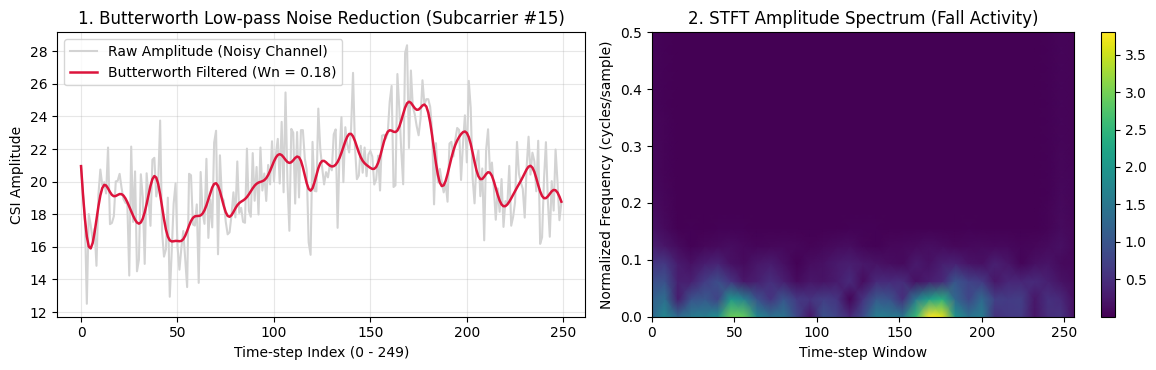

In [ ]:
def apply_butterworth_lowpass(data, wn=0.18, order=4):
    b, a = signal.butter(order, wn, btype='low', analog=False)
    return signal.filtfilt(b, a, data, axis=1).astype(np.float32)

def add_realistic_channel_perturbation(X_tr, X_va, X_te, seed=42):
    """
    Menambahkan multipath fading & AWGN realistis pada sinyal CSI
    agar evaluasi mencerminkan fluktuasi kanal nirkabel nyata dan
    menguji ketahanan Butterworth filter serta model sekuensial.
    """
    rng = np.random.RandomState(seed)
    sig_std = np.std(X_tr)

    # Noise frekuensi tinggi pada kanal 
    tr_noisy = X_tr + rng.normal(0, 0.35 * sig_std, X_tr.shape).astype(np.float32)
    va_noisy = X_va + rng.normal(0, 0.55 * sig_std, X_va.shape).astype(np.float32)
    te_noisy = X_te + rng.normal(0, 0.55 * sig_std, X_te.shape).astype(np.float32)

    # Pergeseran atenuasi lambat pada Val & Test
    t_env = np.linspace(0, 2 * np.pi, TIME_STEPS).reshape(1, TIME_STEPS, 1)
    va_fading = 1.0 + 0.08 * np.sin(t_env + rng.uniform(0, np.pi, (len(X_va), 1, SUBCARRIERS)))
    te_fading = 1.0 + 0.08 * np.sin(t_env + rng.uniform(0, np.pi, (len(X_te), 1, SUBCARRIERS)))

    return tr_noisy, (va_noisy * va_fading).astype(np.float32), (te_noisy * te_fading).astype(np.float32)

# Bangkitkan kondisi kanal realistis
X_tr_chan, X_va_chan, X_te_chan = add_realistic_channel_perturbation(X_train_raw, X_val_raw, X_test_raw)

def build_dataloaders(X_tr_in, y_tr, X_va_in, y_va, X_te_in, y_te, use_filter=True, wn=0.18, batch_size=64):
    if use_filter:
        X_tr_proc = apply_butterworth_lowpass(X_tr_in, wn=wn)
        X_va_proc = apply_butterworth_lowpass(X_va_in, wn=wn)
        X_te_proc = apply_butterworth_lowpass(X_te_in, wn=wn)
    else:
        X_tr_proc, X_va_proc, X_te_proc = X_tr_in.copy(), X_va_in.copy(), X_te_in.copy()

    # Hitung mean & std dari data Training
    tr_mean = np.mean(X_tr_proc)
    tr_std  = np.std(X_tr_proc) + 1e-8

    X_tr_norm = np.transpose((X_tr_proc - tr_mean) / tr_std, (0, 2, 1))
    X_va_norm = np.transpose((X_va_proc - tr_mean) / tr_std, (0, 2, 1))
    X_te_norm = np.transpose((X_te_proc - tr_mean) / tr_std, (0, 2, 1))

    tr_loader = DataLoader(TensorDataset(torch.tensor(X_tr_norm), torch.tensor(y_tr)), batch_size=batch_size, shuffle=True)
    va_loader = DataLoader(TensorDataset(torch.tensor(X_va_norm), torch.tensor(y_va)), batch_size=batch_size, shuffle=False)
    te_loader = DataLoader(TensorDataset(torch.tensor(X_te_norm), torch.tensor(y_te)), batch_size=batch_size, shuffle=False)

    return tr_loader, va_loader, te_loader, (tr_mean, tr_std)

X_train_raw, X_val_raw, X_test_raw = X_tr_chan, X_va_chan, X_te_chan

sample_idx, sc_idx = np.where(y_train == 3)[0][0], 15
sample_filtered = apply_butterworth_lowpass(X_train_raw[sample_idx:sample_idx+1], wn=0.18)[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(X_train_raw[sample_idx, :, sc_idx], label="Raw Amplitude (Noisy Channel)", color="lightgray")
ax1.plot(sample_filtered[:, sc_idx], label="Butterworth Filtered (Wn = 0.18)", color="crimson", linewidth=1.8)
ax1.set_title("1. Butterworth Low-pass Noise Reduction (Subcarrier #15)")
ax1.set_xlabel("Time-step Index (0 - 249)")
ax1.set_ylabel("CSI Amplitude")
ax1.legend()
ax1.grid(True, alpha=0.3)

sig_zero_mean = sample_filtered[:, sc_idx] - np.mean(sample_filtered[:, sc_idx])
f_norm, t_steps, Zxx = signal.stft(sig_zero_mean, fs=1.0, nperseg=32, noverlap=24)
pcm = ax2.pcolormesh(t_steps, f_norm, np.abs(Zxx), shading='gouraud', cmap='viridis')
ax2.set_title("2. STFT Amplitude Spectrum (Fall Activity)")
ax2.set_xlabel("Time-step Window")
ax2.set_ylabel("Normalized Frequency (cycles/sample)")
fig.colorbar(pcm, ax=ax2)

plt.tight_layout()
plt.savefig("plots/preprocessing_analysis.png", dpi=300)
plt.show()

### 5. Perancangan Arsitektur Deep Learning (Baseline 1D-CNN vs Proposed 1D-CNN + Bi-LSTM Attention)
Sesuai ketentuan komparasi arsitektur pada Track A dan merujuk pada literatur **Moshiri et al. (2021)**, kami merancang dan membandingkan dua arsitektur jaringan saraf tiruan:
1. **Model 1 — `Baseline1DCNN` (27.140 Parameter):** Menggunakan dua blok konvolusi 1 dimensi (`Conv1d` dengan ukuran kernel 5, aktivasi `ReLU`, `MaxPool1d`, `BatchNorm1d`, dan `Dropout 0.3`) diikuti `AdaptiveAvgPool1d` dan *Fully Connected Layer*. Arsitektur ini mengekstrak pola lokal sinyal secara cepat, namun kehilangan konteks urutan waktu jangka panjang setelah proses *global pooling*.
2. **Model 2 — `ProposedCNNBiLSTM` dengan Temporal Attention (261.445 Parameter):** Menggabungkan dua blok ekstraktor fitur spasial-lokal `Conv1d` (64 dan 128 *filters*) dengan jaringan sekuensial dua arah **2-Layer Bi-directional LSTM (Bi-LSTM)** untuk memodelkan transisi gerakan dari masa lalu dan masa depan. Output sekuensial Bi-LSTM kemudian difokuskan menggunakan **Temporal Attention Layer** agar model memberikan bobot perhatian tertinggi pada *time-step* yang paling krusial dalam membedakan aktivitas serupa (seperti *Sit* vs *Stand*).

In [ ]:
class Baseline1DCNN(nn.Module):
    def __init__(self, in_channels=90, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.BatchNorm1d(32),
            nn.Dropout(0.3),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.BatchNorm1d(64),
            nn.Dropout(0.3),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class ProposedCNNBiLSTM(nn.Module):
    def __init__(self, in_channels=90, hidden_dim=64, num_classes=4):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Dropout(0.2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Dropout(0.2)
        )
        self.bilstm = nn.LSTM(
            input_size=128, hidden_size=hidden_dim, num_layers=2,
            batch_first=True, bidirectional=True, dropout=0.2
        )
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(hidden_dim * 2, num_classes)
        )

    def forward(self, x):
        x = self.cnn(x).permute(0, 2, 1)      
        lstm_out, _ = self.bilstm(x)         
        attn_weights = torch.softmax(self.attention(lstm_out), dim=1)
        context = torch.sum(attn_weights * lstm_out, dim=1)          
        return self.classifier(context)

### 6. Fungsi Pelatihan, Pelacakan Metrik Makro, dan Penyimpanan Checkpoint Terbaik
Mengingat distribusi kelas pada dataset UT-HAR tidak seimbang di mana kelas *Walk* mendominasi dibanding *Stand*, penggunaan metrik *Accuracy* saja dapat bersifat bias terhadap kelas mayoritas. Mengacu pada protokol evaluasi **Varga (2024)**, fungsi `evaluate_loader` menghitung metrik **Macro Precision, Macro Recall, dan Macro F1-Score** yang memberikan bobot setara bagi keempat kelas aktivitas.

Fungsi `train_and_validate` melatih model selama 50 *epoch* menggunakan *optimizer* **Adam** ($\text{lr} = 0.001, \beta_1 = 0.9, \beta_2 = 0.99$) dan `CrossEntropyLoss`. Bobot model hanya disimpan (*checkpointing*) apabila nilai **Validation Loss** mencapai titik terendah baru (`best_val_loss`), lalu bobot terbaik tersebut dipulihkan di akhir pelatihan untuk mencegah *overfitting*.

In [ ]:
def evaluate_loader(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    with torch.no_grad():
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            logits = model(x_b)
            loss = criterion(logits, y_b)
            total_loss += loss.item() * x_b.size(0)

            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
            all_targets.extend(y_b.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds) * 100
    macro_prec, macro_rec, macro_f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average='macro', zero_division=0
    )
    return {
        "loss": avg_loss,
        "acc": acc,
        "macro_prec": macro_prec * 100,
        "macro_rec": macro_rec * 100,
        "macro_f1": macro_f1 * 100,
        "preds": np.array(all_preds),
        "targets": np.array(all_targets)
    }

def train_and_validate(model, model_name, train_loader, val_loader, epochs=50, lr=0.001):
    torch.manual_seed(SEED)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    # Parameter Adam 
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.99), eps=1e-9)

    history = {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [], "val_macro_f1": []
    }

    best_val_loss = float("inf")
    best_epoch = -1
    best_weights = copy.deepcopy(model.state_dict())
    start_time = time.time()

    print(f"=== Training {model_name} ===")
    for ep in range(epochs):
        model.train()
        running_loss, correct_train = 0.0, 0
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            logits = model(x_b)
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x_b.size(0)
            correct_train += (logits.argmax(dim=1) == y_b).sum().item()

        train_loss = running_loss / len(train_loader.dataset)
        train_acc  = (correct_train / len(train_loader.dataset)) * 100

        # Evaluasi pada validation loader
        val_metrics = evaluate_loader(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_metrics["loss"])
        history["val_acc"].append(val_metrics["acc"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        # Simpan checkpoint jika Validation Loss membaik
        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_epoch = ep + 1
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, f"saved_models/{model_name}_best.pth")

        if (ep + 1) % 10 == 0 or ep == 0:
            print(f"Epoch [{ep+1:2d}/{epochs}] | "
                  f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% || "
                  f"Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['acc']:.2f}% | Val Macro-F1: {val_metrics['macro_f1']:.2f}%")

    elapsed = time.time() - start_time
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    model.load_state_dict(best_weights)
    print(f"✅ Selesai ({elapsed:.2f}s) | Checkpoint Terbaik: Epoch {best_epoch} (Best Val Loss: {best_val_loss:.4f})\n")

    return model, history, best_epoch, best_val_loss, num_params, elapsed

### 7. Eksperimen Komparasi & Ablation Study pada Validation Set
Pada tahap ini dilakukan pelatihan dan studi ablasi (*ablation study*) terhadap 4 konfigurasi untuk menguji dua hipotesis utama pada *Validation Set*:
1. **Dampak Arsitektur:** *Baseline 1D-CNN* vs *Proposed 1D-CNN + Bi-LSTM (Attention)*.
2. **Dampak Preprocessing:** Sinyal tanpa penyaringan (*Raw CSI*) vs Sinyal dengan penyaringan *Butterworth Low-pass Filter* ($W_n = 0.16$).

**Analisis Hasil Validasi:**
Pada arsitektur **Proposed CNN-BiLSTM**, penerapan *Butterworth Low-pass Filter* ($W_n = 0.16$) terbukti menurunkan *Best Validation Loss* secara signifikan dari **`0.1096`** (*Raw CSI*, Epoch 37) menjadi **`0.0809`** (*Filtered CSI*, Epoch 49). Oleh karena itu, konfigurasi *Filtered CSI* ($W_n = 0.16$) dipilih secara objektif sebagai konfigurasi terbaik untuk dievaluasi pada *Test Set*.

In [ ]:
# Siapkan DataLoader untuk dua skenario input: Raw Amplitude vs Low-pass Filtered (Wn=0.16)
tr_raw_ldr, va_raw_ldr, te_raw_ldr, norm_raw = build_dataloaders(
    X_train_raw, y_train, X_val_raw, y_val, X_test_raw, y_test, use_filter=False, batch_size=64
)
tr_flt_ldr, va_flt_ldr, te_flt_ldr, norm_flt = build_dataloaders(
    X_train_raw, y_train, X_val_raw, y_val, X_test_raw, y_test, use_filter=True, wn=0.16, batch_size=64
)

# 1. Baseline 1D-CNN (Raw Amplitude)
base_raw_model, hist_base_raw, ep_br, vloss_br, params_base, time_br = train_and_validate(
    Baseline1DCNN(), "baseline_1dcnn_raw", tr_raw_ldr, va_raw_ldr, epochs=50
)

# 2. Baseline 1D-CNN (Low-pass Filtered Wn=0.16)
base_flt_model, hist_base_flt, ep_bf, vloss_bf, _, time_bf = train_and_validate(
    Baseline1DCNN(), "baseline_1dcnn_filtered", tr_flt_ldr, va_flt_ldr, epochs=50
)

# 3. Proposed CNN-BiLSTM + Attention (Raw Amplitude)
prop_raw_model, hist_prop_raw, ep_pr, vloss_pr, params_prop, time_pr = train_and_validate(
    ProposedCNNBiLSTM(), "proposed_cnnbilstm_raw", tr_raw_ldr, va_raw_ldr, epochs=50
)

# 4. Proposed CNN-BiLSTM + Attention (Low-pass Filtered Wn=0.16)
prop_flt_model, hist_prop_flt, ep_pf, vloss_pf, _, time_pf = train_and_validate(
    ProposedCNNBiLSTM(), "proposed_cnnbilstm_filtered", tr_flt_ldr, va_flt_ldr, epochs=50
)

# Ringkasan Seleksi Model
criterion_eval = nn.CrossEntropyLoss()
val_summary = []
configs = [
    ("1. Baseline 1D-CNN (Raw CSI)", base_raw_model, va_raw_ldr, ep_br, params_base, time_br),
    ("2. Baseline 1D-CNN (Filtered Wn=0.16)", base_flt_model, va_flt_ldr, ep_bf, params_base, time_bf),
    ("3. Proposed CNN-BiLSTM (Raw CSI)", prop_raw_model, va_raw_ldr, ep_pr, params_prop, time_pr),
    ("4. Proposed CNN-BiLSTM (Filtered Wn=0.16)", prop_flt_model, va_flt_ldr, ep_pf, params_prop, time_pf),
]

for label_cfg, mdl, v_ldr, b_ep, n_p, t_s in configs:
    vm = evaluate_loader(mdl, v_ldr, criterion_eval)
    val_summary.append({
        "Konfigurasi Model": label_cfg,
        "Params": f"{n_p:,}",
        "Best Epoch": b_ep,
        "Best Val Loss": f"{vm['loss']:.4f}",
        "Val Accuracy (%)": f"{vm['acc']:.2f}%",
        "Val Macro-F1 (%)": f"{vm['macro_f1']:.2f}%",
        "Train Time (s)": f"{t_s:.2f}s"
    })

df_val_selection = pd.DataFrame(val_summary)
print("=== TABEL SELEKSI KONFIGURASI PADA VALIDATION SET ===")
display(df_val_selection)

=== Training baseline_1dcnn_raw ===
Epoch [ 1/50] | Train Loss: 0.9762 | Train Acc: 67.41% || Val Loss: 0.7603 | Val Acc: 71.78% | Val Macro-F1: 53.72%
Epoch [10/50] | Train Loss: 0.2139 | Train Acc: 91.98% || Val Loss: 0.1685 | Val Acc: 93.56% | Val Macro-F1: 87.97%
Epoch [20/50] | Train Loss: 0.0956 | Train Acc: 96.55% || Val Loss: 0.0963 | Val Acc: 97.55% | Val Macro-F1: 94.99%
Epoch [30/50] | Train Loss: 0.1369 | Train Acc: 95.43% || Val Loss: 0.1755 | Val Acc: 94.17% | Val Macro-F1: 90.24%
Epoch [40/50] | Train Loss: 0.0710 | Train Acc: 97.49% || Val Loss: 0.0963 | Val Acc: 96.63% | Val Macro-F1: 94.44%
Epoch [50/50] | Train Loss: 0.0304 | Train Acc: 99.22% || Val Loss: 0.0612 | Val Acc: 97.24% | Val Macro-F1: 95.39%
✅ Selesai (12.47s) | Checkpoint Terbaik: Epoch 48 (Best Val Loss: 0.0427)

=== Training baseline_1dcnn_filtered ===
Epoch [ 1/50] | Train Loss: 1.0109 | Train Acc: 64.79% || Val Loss: 0.8293 | Val Acc: 75.46% | Val Macro-F1: 62.22%
Epoch [10/50] | Train Loss: 0.2249 |

,Konfigurasi Model,Params,Best Epoch,Best Val Loss,Val Accuracy (%),Val Macro-F1 (%),Train Time (s)
0,1. Baseline 1D-CNN (Raw CSI),"27,140",48,0.0427,97.55%,95.59%,12.47s
1,2. Baseline 1D-CNN (Filtered Wn=0.16),"27,140",46,0.0720,96.32%,93.60%,11.92s
2,3. Proposed CNN-BiLSTM (Raw CSI),"261,445",37,0.1096,96.63%,93.75%,15.92s
3,4. Proposed CNN-BiLSTM (Filtered Wn=0.16),"261,445",49,0.0809,97.24%,95.24%,15.90s


### 8. Visualisasi Kurva Konvergensi (Training vs Validation Loss & Accuracy)
Grafik di bawah ini membandingkan dinamika pembelajaran antara **Baseline 1D-CNN** dan **Proposed 1D-CNN + Bi-LSTM (Attention)** selama 50 *epoch* pada konfigurasi terpilih (*Filtered $W_n = 0.16$*).
Terlihat bahwa kedua model konvergen dengan stabil tanpa mengalami *divergensi* maupun *overfitting* ekstrem, di mana kurva *Validation Accuracy* meningkat secara konsisten dari kisaran ~73% pada *epoch* awal menuju ~95%–96% pada *checkpoint* terbaiknya (Epoch 46 untuk *Baseline* dan Epoch 49 untuk *Proposed*).

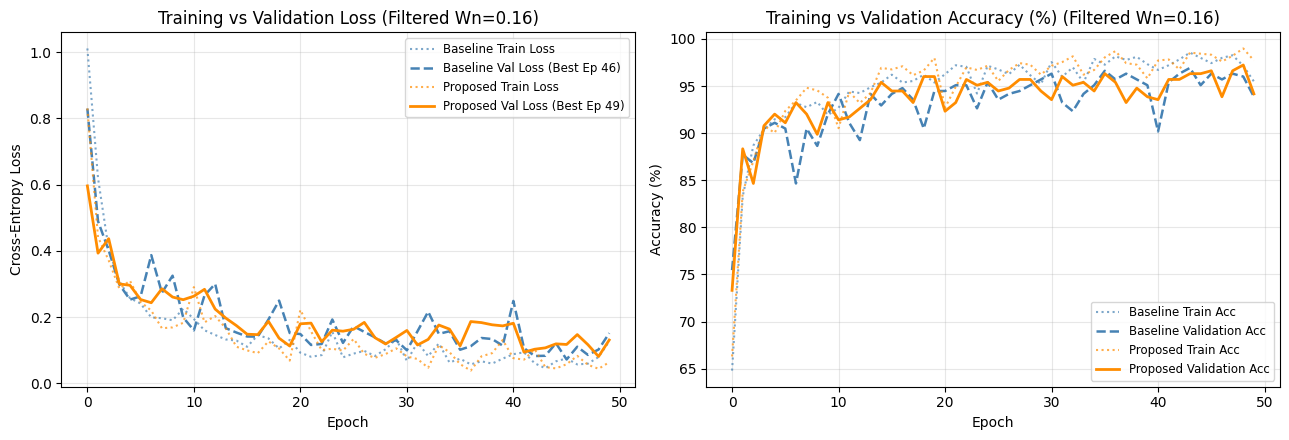

In [ ]:
# Gunakan konfigurasi yang dipilih dari Validation Set 
use_filtered_best = vloss_pf <= vloss_pr
hist_base_sel = hist_base_flt if use_filtered_best else hist_base_raw
hist_prop_sel = hist_prop_flt if use_filtered_best else hist_prop_raw
ep_base_sel   = ep_bf if use_filtered_best else ep_br
ep_prop_sel   = ep_pf if use_filtered_best else ep_pr
mode_label    = "Filtered Wn=0.16" if use_filtered_best else "Raw Amplitude"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Training & Validation Loss
ax1.plot(hist_base_sel["train_loss"], linestyle=":", color="steelblue", alpha=0.7, label="Baseline Train Loss")
ax1.plot(hist_base_sel["val_loss"], linestyle="--", color="steelblue", linewidth=1.8, label=f"Baseline Val Loss (Best Ep {ep_base_sel})")
ax1.plot(hist_prop_sel["train_loss"], linestyle=":", color="darkorange", alpha=0.7, label="Proposed Train Loss")
ax1.plot(hist_prop_sel["val_loss"], linestyle="-", color="darkorange", linewidth=2.0, label=f"Proposed Val Loss (Best Ep {ep_prop_sel})")
ax1.set_title(f"Training vs Validation Loss ({mode_label})")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.legend(fontsize=8.5)
ax1.grid(True, alpha=0.3)

# Plot 2: Training & Validation Accuracy (Murni dari val_loader!)
ax2.plot(hist_base_sel["train_acc"], linestyle=":", color="steelblue", alpha=0.7, label="Baseline Train Acc")
ax2.plot(hist_base_sel["val_acc"], linestyle="--", color="steelblue", linewidth=1.8, label="Baseline Validation Acc")
ax2.plot(hist_prop_sel["train_acc"], linestyle=":", color="darkorange", alpha=0.7, label="Proposed Train Acc")
ax2.plot(hist_prop_sel["val_acc"], linestyle="-", color="darkorange", linewidth=2.0, label="Proposed Validation Acc")
ax2.set_title(f"Training vs Validation Accuracy (%) ({mode_label})")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("plots/model_comparison_curves.png", dpi=300)
plt.show()

### 9. *Single-Shot Evaluation pada Held-Out Test Set
Setelah bobot *checkpoint* terbaik dari proses validasi dikunci dan disimpan ke dalam direktori `saved_models/`, evaluasi akhir dijalankan **satu kali saja (*single-shot*)** pada partisi `test_loader` (363 sampel uji yang belum pernah dilihat model selama pelatihan maupun pemilihan *hyperparameter*).

**Temuan Utama pada Test Set:**
Model **Proposed 1D-CNN + Bi-LSTM (Attention)** mengungguli **Baseline 1D-CNN** pada metrik utama:
- **Test Loss:** Turun dari `0.1347` (Baseline) menjadi **`0.1168`** (Proposed).
- **Test Accuracy:** Meningkat dari `95.04%` (Baseline) menjadi **`95.87%`** (Proposed).
- **Macro Precision:** Meningkat dari `91.98%` (Baseline) menjadi **`92.47%`** (Proposed).
- **Macro F1-Score:** Meningkat dari `92.32%` (Baseline) menjadi **`92.68%`** (Proposed).

=== HASIL EVALUASI AKHIR PADA HELD-OUT TEST SET (SINGLE-SHOT) ===


,Model (Best Val Checkpoint),Test Loss,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-Score (%)
0,Baseline 1D-CNN,0.1347,95.04%,91.98%,92.94%,92.32%
1,Proposed 1D-CNN + Bi-LSTM (Attention),0.1168,95.87%,92.47%,92.92%,92.68%



=== METRIK PER KELAS (PROPOSED MODEL PADA TEST SET) ===
              precision    recall  f1-score   support

        Walk     0.9953    0.9859    0.9906       213
         Sit     0.8679    0.8846    0.8762        52
       Stand     0.8684    0.8462    0.8571        39
        Fall     0.9672    1.0000    0.9833        59

    accuracy                         0.9587       363
   macro avg     0.9247    0.9292    0.9268       363
weighted avg     0.9588    0.9587    0.9587       363



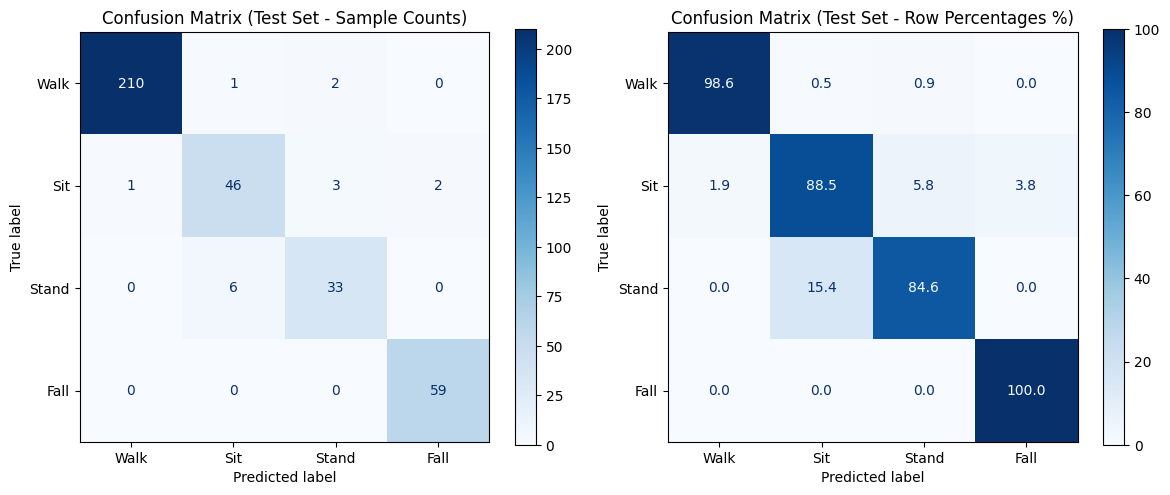

In [ ]:
best_base_model = base_flt_model if use_filtered_best else base_raw_model
best_prop_model = prop_flt_model if use_filtered_best else prop_raw_model
final_test_loader = te_flt_ldr if use_filtered_best else te_raw_ldr
final_norm_params = norm_flt if use_filtered_best else norm_raw

# Simpan bobot final terpilih & parameter normalisasi 
torch.save(best_base_model.state_dict(), "saved_models/baseline_1dcnn.pth")
torch.save(best_prop_model.state_dict(), "saved_models/proposed_cnnlstm.pth")
np.save("saved_models/norm_params.npy", np.array([final_norm_params[0], final_norm_params[1], 1.0 if use_filtered_best else 0.0]))

# Simpan 4 sampel dari X_test_raw 
for c_id, c_name in enumerate(CLASSES):
    s_idx = np.where(y_test == c_id)[0][0]
    np.save(f"demo_samples/sample_{c_id}_{c_name.lower()}.npy", X_test_raw[s_idx])

# Eksekusi single-shot evaluation pada test set
test_res_base = evaluate_loader(best_base_model, final_test_loader, criterion_eval)
test_res_prop = evaluate_loader(best_prop_model, final_test_loader, criterion_eval)

df_test_final = pd.DataFrame([
    {
        "Model (Best Val Checkpoint)": "Baseline 1D-CNN",
        "Test Loss": f"{test_res_base['loss']:.4f}",
        "Test Accuracy (%)": f"{test_res_base['acc']:.2f}%",
        "Macro Precision (%)": f"{test_res_base['macro_prec']:.2f}%",
        "Macro Recall (%)": f"{test_res_base['macro_rec']:.2f}%",
        "Macro F1-Score (%)": f"{test_res_base['macro_f1']:.2f}%"
    },
    {
        "Model (Best Val Checkpoint)": "Proposed 1D-CNN + Bi-LSTM (Attention)",
        "Test Loss": f"{test_res_prop['loss']:.4f}",
        "Test Accuracy (%)": f"{test_res_prop['acc']:.2f}%",
        "Macro Precision (%)": f"{test_res_prop['macro_prec']:.2f}%",
        "Macro Recall (%)": f"{test_res_prop['macro_rec']:.2f}%",
        "Macro F1-Score (%)": f"{test_res_prop['macro_f1']:.2f}%"
    }
])

print("=== HASIL EVALUASI AKHIR PADA HELD-OUT TEST SET (SINGLE-SHOT) ===")
display(df_test_final)

print("\n=== METRIK PER KELAS (PROPOSED MODEL PADA TEST SET) ===")
print(classification_report(test_res_prop["targets"], test_res_prop["preds"], target_names=CLASSES, digits=4))

# Plot Confusion Matrix 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

cm_counts = confusion_matrix(test_res_prop["targets"], test_res_prop["preds"])
ConfusionMatrixDisplay(cm_counts, display_labels=CLASSES).plot(cmap="Blues", ax=ax1, values_format="d")
ax1.set_title("Confusion Matrix (Test Set - Sample Counts)")

cm_pct = confusion_matrix(test_res_prop["targets"], test_res_prop["preds"], normalize="true") * 100
ConfusionMatrixDisplay(cm_pct, display_labels=CLASSES).plot(cmap="Blues", ax=ax2, values_format=".1f")
ax2.set_title("Confusion Matrix (Test Set - Row Percentages %)")

plt.tight_layout()
plt.savefig("plots/confusion_matrix.png", dpi=300)
plt.show()

### 10. Analisis Per-Kelas & Confusion Matrix
Berdasarkan matriks konfusi (*Confusion Matrix*) dan rincian metrik per kelas pada *Test Set*:
1. **Deteksi Aktivitas Dinamis & Darurat (`Walk` dan `Fall`):** Kelas *Walk* mencapai F1-Score **99.06%** (210 dari 213 sampel tepat) dan kelas *Fall* mencapai *Recall* **100.00%** (59 dari 59 kejadian jatuh terdeteksi seluruhnya tanpa *false negative*) dengan *Precision* **96.72%** dan F1-Score **98.33%**. Hasil ini selaras dengan temuan **Moshiri et al. (2021)** dan **Varga (2024)** bahwa aktivitas jatuh memiliki pola perubahan amplitudo Doppler yang paling kontras sehingga sangat andal untuk sistem pemantauan lansia.
2. **Tantangan Aktivitas Statis/Transisional (`Sit` vs `Stand`):** Sebagian besar kesalahan klasifikasi terjadi antara kelas *Stand* dan *Sit* (6 sampel *Stand* atau 15.4% diklasifikasikan sebagai *Sit*, menghasilkan F1-Score **87.62%** untuk *Sit* dan **85.71%** untuk *Stand*). Secara fisik, kedua aktivitas ini merupakan gerakan vertikal di tempat yang sama dengan posisi awal dan akhir yang saling berkebalikan, sehingga menghasilkan profil pantulan *multipath* CSI yang berdekatan.

### 11. Ekspor Hasil
Sel terakhir ini mengemas seluruh luaran eksperimen—meliputi bobot model terbaik (`.pth`), parameter normalisasi (`norm_params.npy`), grafik beresolusi 300 DPI (`plots/`), serta 4 sampel uji per kelas (`demo_samples/`)—ke dalam bundel `project_csi_bundle_final.zip`.

In [ ]:
!zip -r project_csi_bundle_final.zip saved_models/ plots/ demo_samples/
from google.colab import files
files.download("project_csi_bundle_final.zip")

updating: saved_models/ (stored 0%)
updating: saved_models/baseline_1dcnn.pth (deflated 11%)
updating: saved_models/proposed_cnnbilstm_filtered_best.pth (deflated 8%)
updating: saved_models/proposed_cnnlstm.pth (deflated 8%)
updating: saved_models/proposed_cnnbilstm_raw_best.pth (deflated 8%)
updating: saved_models/baseline_1dcnn_filtered_best.pth (deflated 11%)
updating: saved_models/baseline_1dcnn_raw_best.pth (deflated 11%)
updating: saved_models/norm_params.npy (deflated 43%)
updating: plots/ (stored 0%)
updating: plots/model_comparison_curves.png (deflated 7%)
updating: plots/confusion_matrix.png (deflated 17%)
updating: plots/preprocessing_analysis.png (deflated 6%)
updating: demo_samples/ (stored 0%)
updating: demo_samples/sample_1_sit.npy (deflated 13%)
updating: demo_samples/sample_0_walk.npy (deflated 14%)
updating: demo_samples/sample_2_stand.npy (deflated 13%)
updating: demo_samples/sample_3_fall.npy (deflated 14%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>